In [1]:
# Upgrade the Hugging Face libraries
!pip install -q -U datasets huggingface_hub

# --- CONSOLIDATED IMPORTS ---
import math
import random
import copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import ImageFilter
from sklearn.manifold import TSNE

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from datasets import load_dataset

# --- DEVICE SETUP ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# --- DATASET PREPARATION ---
print("Downloading CIFAR-10 from Hugging Face...")
hf_dataset = load_dataset("uoft-cs/cifar10", split="train")

class HFCIFAR10(Dataset):
    def __init__(self, hf_data, transform=None):
        self.data = hf_data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        img = item['img']
        label = item['label']
        if self.transform:
            img = self.transform(img)
        return img, label

base_transform = transforms.Compose([transforms.ToTensor()])
full_dataset = HFCIFAR10(hf_dataset, transform=base_transform)

# Limit to 5,000 images
np.random.seed(42)
subset_indices = np.random.choice(len(full_dataset), 5000, replace=False)
mini_cifar_dataset = Subset(full_dataset, subset_indices)

print(f"Mini-DINO dataset size: {len(mini_cifar_dataset)} images")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 838.0/838.0 kB 54.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 16.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 25.0.1 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.1.1 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.1.1 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.1.1 which is incompatible.
Using device: cuda


README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Mini-DINO dataset size: 5000 images


In [2]:
# -------------------------------------------------------------
# 2. Multi-Crop Augmentation Pipeline
# -------------------------------------------------------------

# Custom Gaussian Blur as used in the DINO paper
class GaussianBlur(object):
    def __init__(self, p=0.5, radius_min=0.1, radius_max=2.0):
        self.prob = p
        self.radius_min = radius_min
        self.radius_max = radius_max

    def __call__(self, img):
        if random.random() < self.prob:
            return img.filter(ImageFilter.GaussianBlur(
                radius=random.uniform(self.radius_min, self.radius_max)
            ))
        return img

class DataAugmentationDINO(object):
    def __init__(self, global_crops_scale, local_crops_scale, local_crops_number):
        # Standard Normalization for CIFAR-10
        normalize = transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                                         std=[0.2470, 0.2435, 0.2616])

        color_jitter = transforms.ColorJitter(0.4, 0.4, 0.2, 0.1)

        # 1. Global Crop 1
        self.global_transfo1 = transforms.Compose([
            transforms.RandomResizedCrop(32, scale=global_crops_scale, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomApply([color_jitter], p=0.8),
            transforms.RandomGrayscale(p=0.2),
            GaussianBlur(p=1.0),
            transforms.ToTensor(),
            normalize,
        ])

        # 2. Global Crop 2 (slightly different augmentations)
        self.global_transfo2 = transforms.Compose([
            transforms.RandomResizedCrop(32, scale=global_crops_scale, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomApply([color_jitter], p=0.8),
            transforms.RandomGrayscale(p=0.2),
            GaussianBlur(p=0.1),
            transforms.RandomSolarize(128, p=0.2),
            transforms.ToTensor(),
            normalize,
        ])

        # 3. Local Crops (Smaller resolution, passed only to Student)
        self.local_crops_number = local_crops_number
        self.local_transfo = transforms.Compose([
            transforms.RandomResizedCrop(16, scale=local_crops_scale, interpolation=transforms.InterpolationMode.BICUBIC),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomApply([color_jitter], p=0.8),
            transforms.RandomGrayscale(p=0.2),
            GaussianBlur(p=0.5),
            transforms.ToTensor(),
            normalize,
        ])

    def __call__(self, image):
        crops = []
        crops.append(self.global_transfo1(image))
        crops.append(self.global_transfo2(image))
        for _ in range(self.local_crops_number):
            crops.append(self.local_transfo(image))
        return crops

# Create the Multi-Crop Augmentation pipeline
dino_transform = DataAugmentationDINO(
    global_crops_scale=(0.5, 1.),
    local_crops_scale=(0.15, 0.5),
    local_crops_number=4
)

# Update our previously downloaded dataset to use this new transform
full_dataset.transform = dino_transform

print("Multi-crop augmentation pipeline is ready!")

Multi-crop augmentation pipeline is ready!


In [5]:
# -------------------------------------------------------------
# 3. DataLoader, Architecture, & Loss Setup
# -------------------------------------------------------------

# --- DataLoader ---
def collate_fn_dino(batch):
    crops = [[] for _ in range(len(batch[0][0]))]
    labels = []
    for sample, label in batch:
        for i, crop in enumerate(sample): crops[i].append(crop)
        labels.append(label)
    return [torch.stack(c) for c in crops], torch.tensor(labels)

train_loader = DataLoader(
    mini_cifar_dataset, batch_size=64, shuffle=True,
    num_workers=2, drop_last=True, collate_fn=collate_fn_dino
)

# --- Backbone (TinyViT) ---
class PatchEmbed(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_chans=3, embed_dim=192):
        super().__init__()
        self.patch_size = patch_size
        self.num_patches = (img_size // patch_size) ** 2
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
    def forward(self, x): return self.proj(x).flatten(2).transpose(1, 2)

class Attention(nn.Module):
    def __init__(self, dim, num_heads=3):
        super().__init__()
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3, bias=False)
        self.proj = nn.Linear(dim, dim)
    def forward(self, x, return_attention=False):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        attn = (q @ k.transpose(-2, -1) * self.scale).softmax(dim=-1)
        out = self.proj((attn @ v).transpose(1, 2).reshape(B, N, C))
        return (out, attn) if return_attention else out

class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio=4.0):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.attn = Attention(dim, num_heads=num_heads)
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(), nn.Linear(int(dim * mlp_ratio), dim))
    def forward(self, x, return_attention=False):
        if return_attention:
            attn_out, attn_weights = self.attn(self.norm1(x), return_attention=True)
            return x + attn_out + self.mlp(self.norm2(x + attn_out)), attn_weights
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))

class TinyViT(nn.Module):
    def __init__(self, embed_dim=192, depth=6):
        super().__init__()
        self.patch_embed = PatchEmbed(embed_dim=embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.patch_embed.num_patches + 1, embed_dim))
        self.blocks = nn.ModuleList([TransformerBlock(embed_dim, num_heads=3) for _ in range(depth)])
        self.norm = nn.LayerNorm(embed_dim)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def interpolate_pos_encoding(self, x, w, h):
        N = self.pos_embed.shape[1] - 1
        if (x.shape[1] - 1) == N and w == h: return self.pos_embed
        orig_size = int(math.sqrt(N))
        patch_pos = F.interpolate(
            self.pos_embed[:, 1:].reshape(1, orig_size, orig_size, -1).permute(0, 3, 1, 2),
            scale_factor=((w // 4 + 0.1) / orig_size, (h // 4 + 0.1) / orig_size), mode='bicubic', align_corners=False
        )
        return torch.cat((self.pos_embed[:, 0].unsqueeze(0), patch_pos.permute(0, 2, 3, 1).view(1, -1, x.shape[-1])), dim=1)

    def forward(self, x, return_attention=False):
        # FIX IS HERE: We capture w and h before updating x!
        w, h = x.shape[2], x.shape[3]

        x = torch.cat((self.cls_token.expand(x.shape[0], -1, -1), self.patch_embed(x)), dim=1)
        x = x + self.interpolate_pos_encoding(x, w, h)
        for i, blk in enumerate(self.blocks):
            if return_attention and i == len(self.blocks) - 1: x, attn = blk(x, return_attention=True)
            else: x = blk(x)
        return (self.norm(x)[:, 0], attn) if return_attention else self.norm(x)[:, 0]

# --- DINO Head & Full Model ---
class FullDINOModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = TinyViT()
        self.head_mlp = nn.Sequential(nn.Linear(192, 256), nn.GELU(), nn.Linear(256, 256), nn.GELU(), nn.Linear(256, 128))
        self.head_last = nn.utils.parametrizations.weight_norm(nn.Linear(128, 1024, bias=False))
        self.head_last.parametrizations.weight.original0.data.fill_(1)
        self.head_last.parametrizations.weight.original0.requires_grad = False

    def forward(self, x):
        return self.head_last(F.normalize(self.head_mlp(self.backbone(x)), dim=-1, p=2))

# --- Loss & EMA ---
class DINOLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer("center", torch.zeros(1, 1024))
    def forward(self, student_outs, teacher_outs):
        total_loss = 0
        for i, t_out in enumerate(teacher_outs):
            t_out = F.softmax((t_out - self.center) / 0.04, dim=-1).detach()
            for j, s_out in enumerate(student_outs):
                if i != j: total_loss += torch.sum(-t_out * F.log_softmax(s_out / 0.1, dim=-1), dim=-1).mean()
        # Update center
        self.center = self.center * 0.9 + torch.cat(teacher_outs).mean(dim=0, keepdim=True) * 0.1
        return total_loss / (len(teacher_outs) * (len(student_outs) - 1))

def update_ema(student_model, teacher_model, momentum=0.996):
    with torch.no_grad():
        for s_param, t_param in zip(student_model.parameters(), teacher_model.parameters()):
            t_param.data.mul_(momentum).add_((1 - momentum) * s_param.data)

print("DataLoader, Architecture, and Loss setup complete!")

DataLoader, Architecture, and Loss setup complete!



--- Starting Training (With EMA) ---
Epoch 1/10 | Loss: 6.7102
Epoch 2/10 | Loss: 6.8147
Epoch 3/10 | Loss: 6.7921
Epoch 4/10 | Loss: 6.7646
Epoch 5/10 | Loss: 6.7212
Epoch 6/10 | Loss: 6.6885
Epoch 7/10 | Loss: 6.6596
Epoch 8/10 | Loss: 6.6250
Epoch 9/10 | Loss: 6.6028
Epoch 10/10 | Loss: 6.5793

--- Starting Training (No EMA) ---
Epoch 1/5 | Loss: 6.7060
Epoch 2/5 | Loss: 6.7331
Epoch 3/5 | Loss: 6.7297
Epoch 4/5 | Loss: 6.7272
Epoch 5/5 | Loss: 6.7263


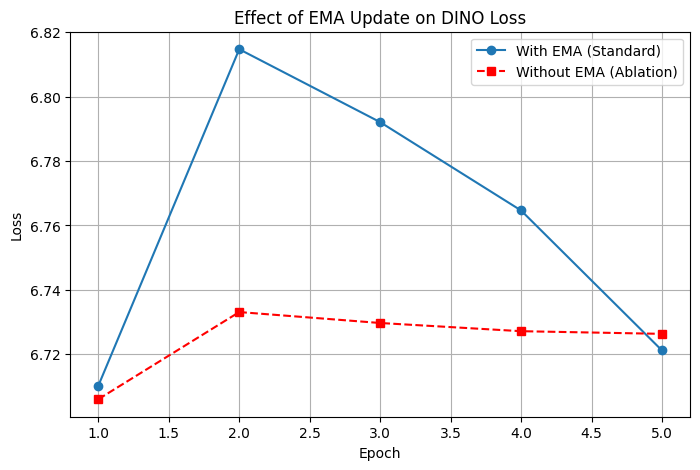

In [6]:
# -------------------------------------------------------------
# 4. Unified Training & Ablation Loop
# -------------------------------------------------------------

def train_dino(epochs, use_ema=True):
    # Initialize fresh models and optimizers for each run
    mod_student = FullDINOModel().to(device)
    mod_teacher = FullDINOModel().to(device)
    mod_teacher.load_state_dict(mod_student.state_dict())
    for p in mod_teacher.parameters(): p.requires_grad = False

    opt = torch.optim.AdamW(mod_student.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = DINOLoss().to(device)
    history = []

    print(f"\n--- Starting Training ({'With EMA' if use_ema else 'No EMA'}) ---")
    for epoch in range(epochs):
        mod_student.train()
        total_loss = 0.0

        for crops, _ in train_loader:
            crops = [c.to(device) for c in crops]

            with torch.no_grad():
                t_out = [mod_teacher(c) for c in crops[:2]] # Global crops only

            s_out = [mod_student(c) for c in crops] # All crops
            loss = loss_fn(s_out, t_out)

            opt.zero_grad()
            loss.backward()
            opt.step()

            if use_ema: update_ema(mod_student, mod_teacher)
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        history.append(avg_loss)
        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")

    return mod_student, mod_teacher, history

# 1. Run Standard Training
student, teacher, loss_history = train_dino(epochs=10, use_ema=True)

# 2. Run Ablation Study (No EMA)
_, _, ablation_history = train_dino(epochs=5, use_ema=False)

# 3. Plot Comparison
plt.figure(figsize=(8, 5))
plt.plot(range(1, 6), loss_history[:5], marker='o', label='With EMA (Standard)')
plt.plot(range(1, 6), ablation_history, marker='s', linestyle='--', color='r', label='Without EMA (Ablation)')
plt.title("Effect of EMA Update on DINO Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

Starting Visualizations...
Extracting embeddings for t-SNE (this takes a few seconds)...


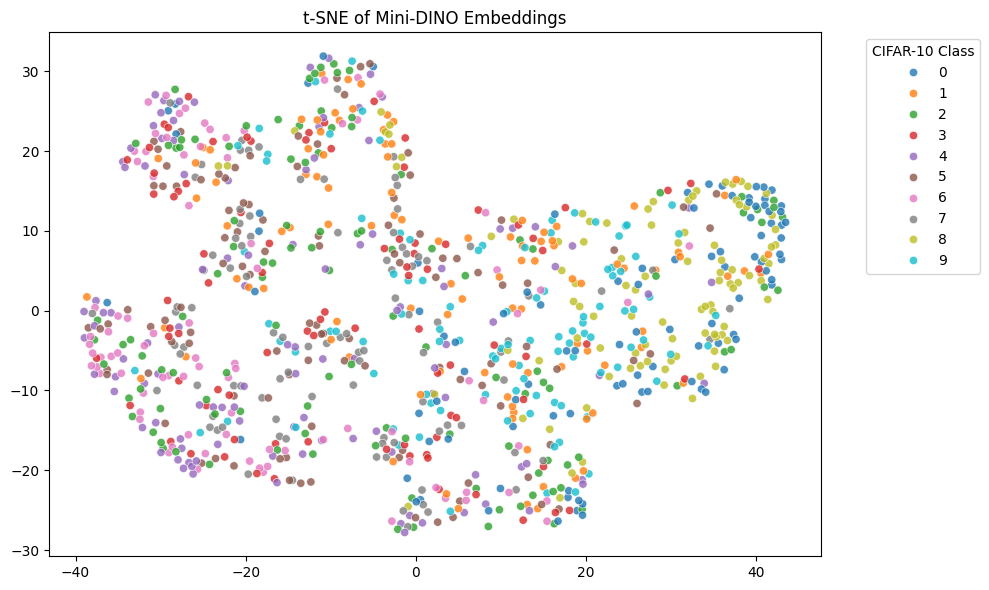

Generating Attention Maps...


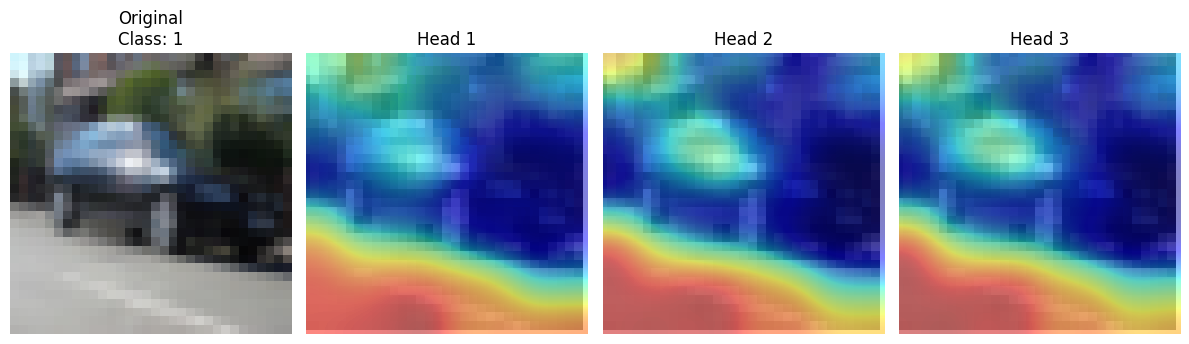

In [7]:
# -------------------------------------------------------------
# 5. Visualizations: t-SNE & Attention Maps
# -------------------------------------------------------------
print("Starting Visualizations...")

# --- Setup Evaluation Data ---
eval_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2470, 0.2435, 0.2616])
])
eval_dataset = HFCIFAR10(hf_dataset, transform=eval_transform)
eval_loader = DataLoader(Subset(eval_dataset, range(1000)), batch_size=64, shuffle=False)

# -------------------------------------------------------------
# 5A. Extract Embeddings & Plot t-SNE
# -------------------------------------------------------------
print("Extracting embeddings for t-SNE (this takes a few seconds)...")
student.eval()
all_embeds, all_labels = [], []

with torch.no_grad():
    for imgs, labels in eval_loader:
        all_embeds.append(student.backbone(imgs.to(device)).cpu().numpy())
        all_labels.append(labels.numpy())

# Run t-SNE dimension reduction
embeds_2d = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(np.concatenate(all_embeds))
labels_cat = np.concatenate(all_labels)

# Plot t-SNE
plt.figure(figsize=(10, 6))
sns.scatterplot(x=embeds_2d[:, 0], y=embeds_2d[:, 1], hue=labels_cat, palette="tab10", legend="full", alpha=0.8)
plt.title("t-SNE of Mini-DINO Embeddings")
plt.legend(title="CIFAR-10 Class", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 5B. Generate ViT Attention Maps
# -------------------------------------------------------------
print("Generating Attention Maps...")
img_tensor, label = eval_dataset[14] # Grab a sample image (index 14)

teacher.eval()
with torch.no_grad():
    # Extract attention weights from Teacher
    _, attn = teacher.backbone(img_tensor.unsqueeze(0).to(device), return_attention=True)

num_heads = attn.shape[1]
# Extract CLS attention and reshape to 8x8 spatial grid
cls_attn = attn[0, :, 0, 1:].reshape(num_heads, 8, 8).cpu().numpy()

# Unnormalize image for displaying
img_show = np.clip(img_tensor.permute(1, 2, 0).numpy() * np.array([0.2470, 0.2435, 0.2616]) + np.array([0.4914, 0.4822, 0.4465]), 0, 1)

# Plot original image + attention heads
fig, axes = plt.subplots(1, num_heads + 1, figsize=(12, 4))
axes[0].imshow(img_show)
axes[0].set_title(f"Original\nClass: {label}")
axes[0].axis('off')

for i in range(num_heads):
    axes[i+1].imshow(img_show)
    axes[i+1].imshow(cls_attn[i], cmap='jet', alpha=0.5, extent=(0, 32, 32, 0), interpolation='bicubic')
    axes[i+1].set_title(f"Head {i+1}")
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()